# 🔍 Glass Identification — Preparação de Dados para Árvore de Decisão

**Dataset:** [UCI Glass Identification](https://archive.ics.uci.edu/dataset/42/glass+identification)  
**Tarefa:** Classificação multiclasse (6 tipos de vidro)  
**Instâncias:** 214 | **Features:** 9 (todas contínuas) | **Valores ausentes:** Nenhum

---
### Etapas do pipeline:
1. Instalação de dependências
2. Carregamento dos dados
3. Análise exploratória (EDA)
4. Remoção do ID e verificação de duplicatas
5. Detecção e tratamento de outliers
6. Análise e balanceamento de classes (SMOTE)
7. Engenharia de features
8. Divisão estratificada dos dados
9. Treinamento e otimização da Árvore de Decisão
10. Avaliação e visualização dos resultados

## 📦 Etapa 1 — Instalação de Dependências

In [ ]:
!pip install ucimlrepo imbalanced-learn --quiet

## 📥 Etapa 2 — Carregamento dos Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from ucimlrepo import fetch_ucirepo

# Carrega o dataset diretamente do repositório UCI
glass_identification = fetch_ucirepo(id=42)

X = glass_identification.data.features.copy()
y = glass_identification.data.targets.copy()

# Unifica em um único DataFrame para exploração
df = pd.concat([X, y], axis=1)
df.columns = list(X.columns) + ['Type']

print('✅ Dataset carregado com sucesso!')
print(f'   Shape: {df.shape}')
print(f'   Features: {list(X.columns)}')
df.head()

✅ Dataset carregado com sucesso!
   Shape: (214, 10)
   Features: ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


## 🔎 Etapa 3 — Análise Exploratória (EDA)

In [ ]:
print('=== INFORMAÇÕES GERAIS ===')
df.info()
print()
print('=== ESTATÍSTICAS DESCRITIVAS ===')
df.describe().round(4)

=== INFORMAÇÕES GERAIS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB

=== ESTATÍSTICAS DESCRITIVAS ===


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.0000,214.0000,214.0000,214.0000,214.0000,214.0000,214.0000,214.0000,214.0000,214.0000
mean,1.5184,13.4079,2.6845,1.4449,72.6509,0.4971,8.9570,0.1750,0.0570,2.7804
std,0.0030,0.8166,1.4424,0.4993,0.7745,0.6522,1.4232,0.4972,0.0974,2.1037
min,1.5112,10.7300,0.0000,0.2900,69.8100,0.0000,5.4300,0.0000,0.0000,1.0000
25%,1.5165,12.9075,2.1150,1.1900,72.2800,0.1225,8.2400,0.0000,0.0000,1.0000
50%,1.5177,13.3000,3.4800,1.3600,72.7900,0.5550,8.6000,0.0000,0.0000,2.0000
75%,1.5192,13.8250,3.6000,1.6300,73.0875,0.6100,9.1725,0.0000,0.1000,3.0000
max,1.5339,17.3800,4.4900,3.5000,75.4100,6.2100,16.1900,3.1500,0.5100,7.0000


In [ ]:
print('=== VALORES AUSENTES ===')
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else '✅ Nenhum valor ausente encontrado.')

=== VALORES AUSENTES ===
✅ Nenhum valor ausente encontrado.


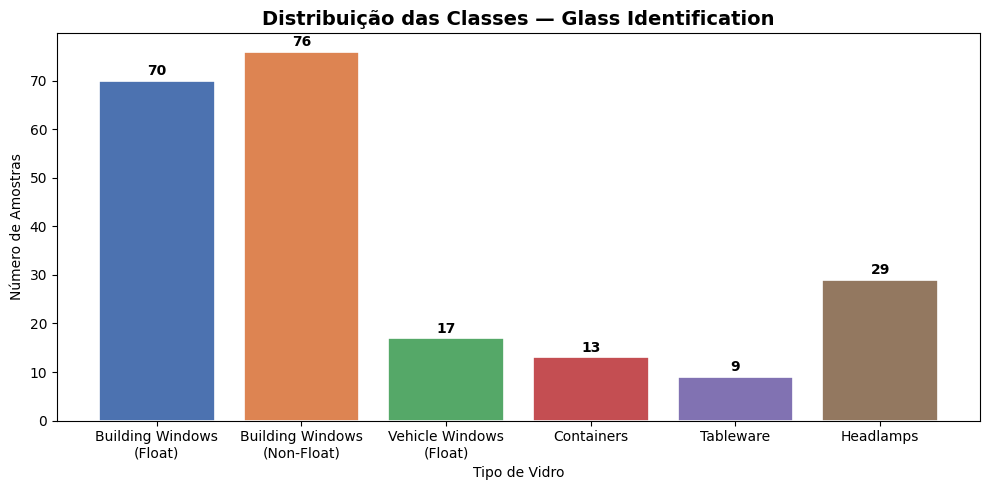


⚠️  Dataset fortemente desbalanceado:
   Classe 1 (Building Windows
(Float)): 70 amostras (32.7%)
   Classe 2 (Building Windows
(Non-Float)): 76 amostras (35.5%)
   Classe 3 (Vehicle Windows
(Float)): 17 amostras (7.9%)
   Classe 5 (Containers): 13 amostras (6.1%)
   Classe 6 (Tableware): 9 amostras (4.2%)
   Classe 7 (Headlamps): 29 amostras (13.6%)


In [ ]:
# Distribuição das classes
nomes_classes = {
    1: 'Building Windows\n(Float)',
    2: 'Building Windows\n(Non-Float)',
    3: 'Vehicle Windows\n(Float)',
    5: 'Containers',
    6: 'Tableware',
    7: 'Headlamps'
}

contagem = df['Type'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(
    [nomes_classes.get(i, str(i)) for i in contagem.index],
    contagem.values,
    color=['#4C72B0','#DD8452','#55A868','#C44E52','#8172B2','#937860'],
    edgecolor='white', linewidth=1.2
)
for bar, val in zip(bars, contagem.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            str(val), ha='center', va='bottom', fontweight='bold')

ax.set_title('Distribuição das Classes — Glass Identification', fontsize=14, fontweight='bold')
ax.set_ylabel('Número de Amostras')
ax.set_xlabel('Tipo de Vidro')
plt.tight_layout()
plt.show()

print('\n⚠️  Dataset fortemente desbalanceado:')
for cls, cnt in contagem.items():
    print(f'   Classe {cls} ({nomes_classes.get(cls,"?")}): {cnt} amostras ({cnt/len(df)*100:.1f}%)')

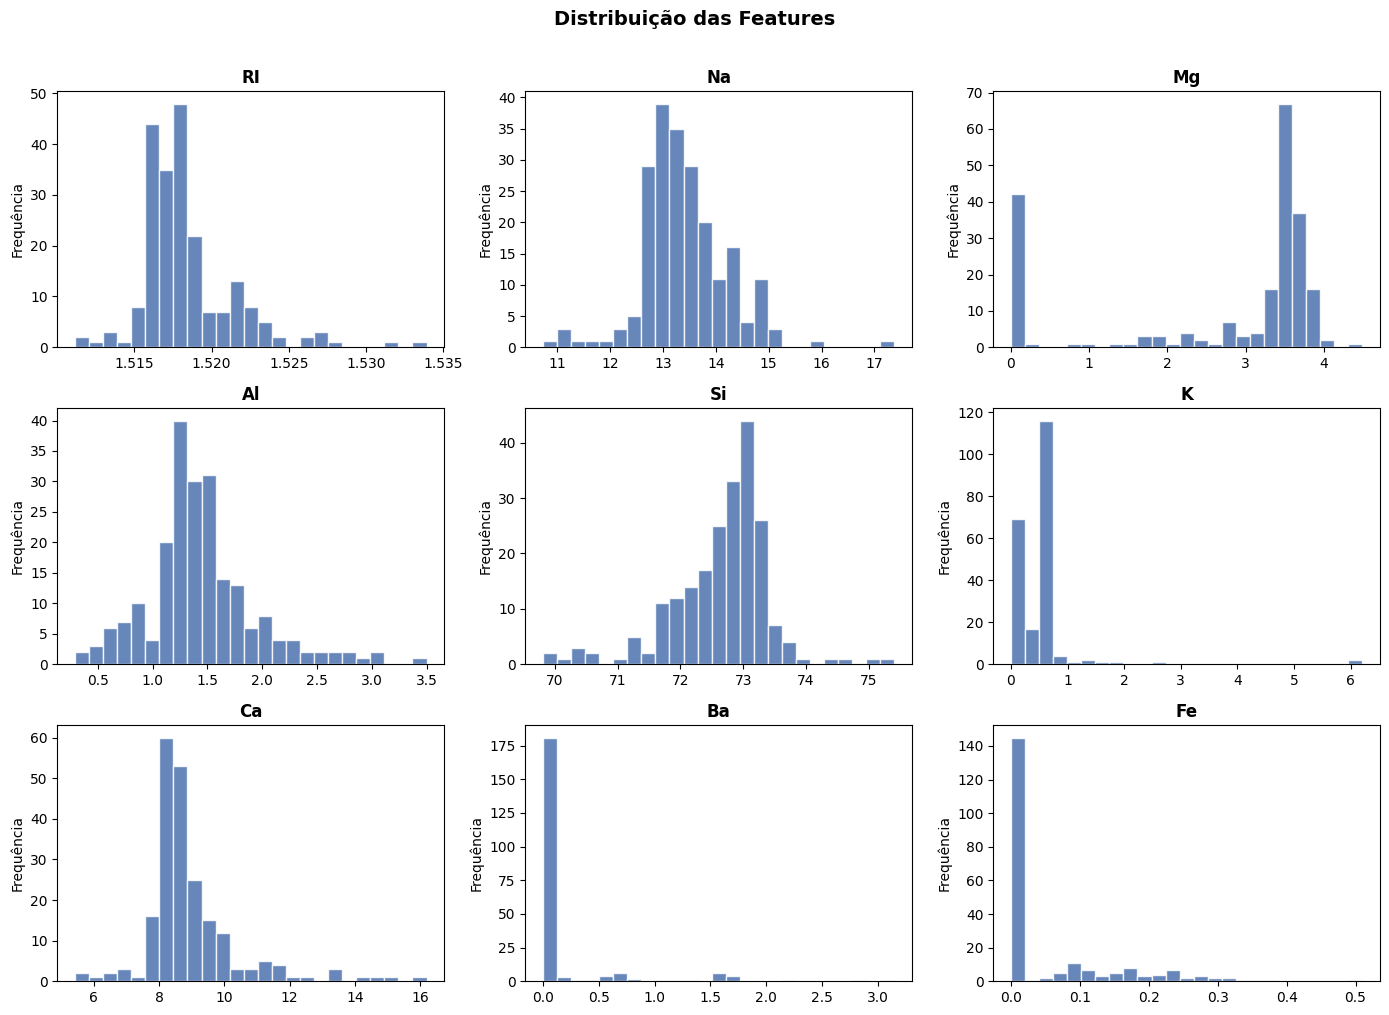


⚠️  Notas importantes:
   - Ba e Fe têm distribuição muito esparsa (muitos zeros)
   - Si tem distribuição quase normal (dominante em peso)
   - RI tem variação muito pequena em escala absoluta


In [ ]:
# Distribuição das features
features = list(X.columns)

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for i, feat in enumerate(features):
    axes[i].hist(df[feat], bins=25, color='#4C72B0', edgecolor='white', alpha=0.85)
    axes[i].set_title(feat, fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Frequência')

plt.suptitle('Distribuição das Features', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print('\n⚠️  Notas importantes:')
print('   - Ba e Fe têm distribuição muito esparsa (muitos zeros)')
print('   - Si tem distribuição quase normal (dominante em peso)')
print('   - RI tem variação muito pequena em escala absoluta')

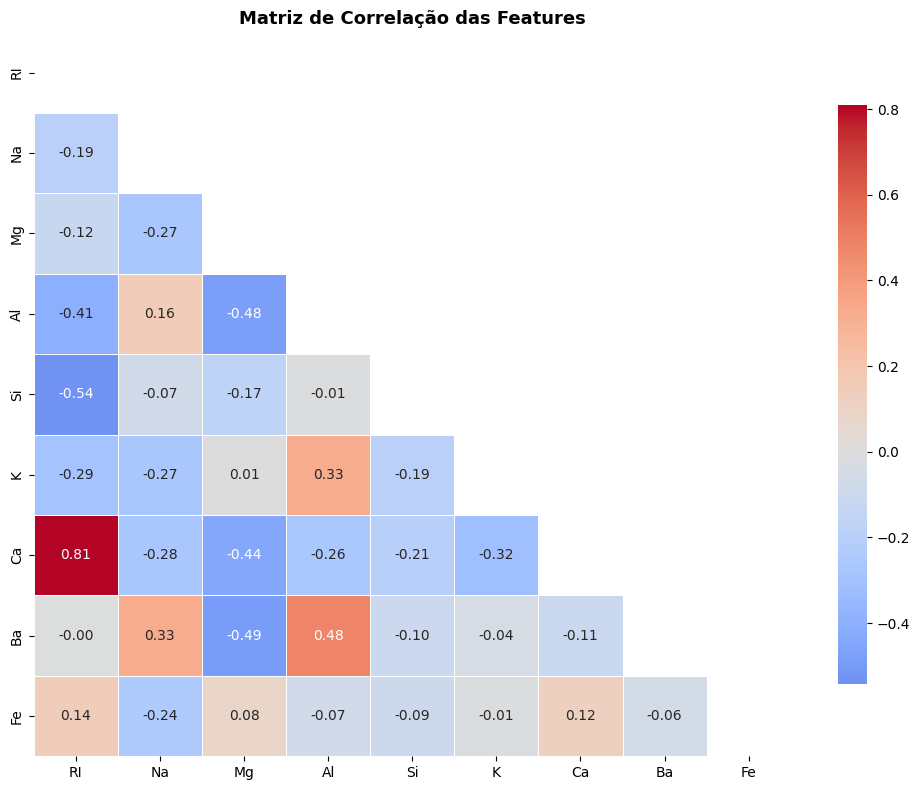


=== PARES COM CORRELAÇÃO ALTA (|r| > 0.5) ===
   Si × RI: -0.542
   Ca × RI: 0.810


In [ ]:
# Mapa de correlação
fig, ax = plt.subplots(figsize=(10, 8))
corr = df[features].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Matriz de Correlação das Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Identifica correlações altas
print('\n=== PARES COM CORRELAÇÃO ALTA (|r| > 0.5) ===')
for i in range(len(corr.columns)):
    for j in range(i):
        val = corr.iloc[i, j]
        if abs(val) > 0.5:
            print(f'   {corr.columns[i]} × {corr.columns[j]}: {val:.3f}')

## 🗑️ Etapa 4 — Remoção do ID e Duplicatas

In [ ]:
# O Id_number não existe nas features do ucimlrepo, mas verificamos por precaução
cols_id = [c for c in df.columns if 'id' in c.lower() or 'Id' in c]
if cols_id:
    df.drop(columns=cols_id, inplace=True)
    print(f'✅ Colunas de ID removidas: {cols_id}')
else:
    print('✅ Nenhuma coluna de ID presente nas features.')

# Verificação e remoção de duplicatas
n_antes = len(df)
df.drop_duplicates(inplace=True)
n_depois = len(df)
print(f'✅ Duplicatas removidas: {n_antes - n_depois} | Registros restantes: {n_depois}')

# Atualiza X e y
X = df.drop(columns=['Type'])
y = df['Type']

✅ Nenhuma coluna de ID presente nas features.
✅ Duplicatas removidas: 1 | Registros restantes: 213


## 📊 Etapa 5 — Detecção e Tratamento de Outliers

> ⚠️ **Nota:** Árvores de decisão são naturalmente robustas a outliers, pois usam limiares de corte. Porém, outliers extremos em features esparsas como `Ba` e `Fe` podem criar **splits espúrios** — divisões que capturam apenas ruído pontual, levando ao overfitting.

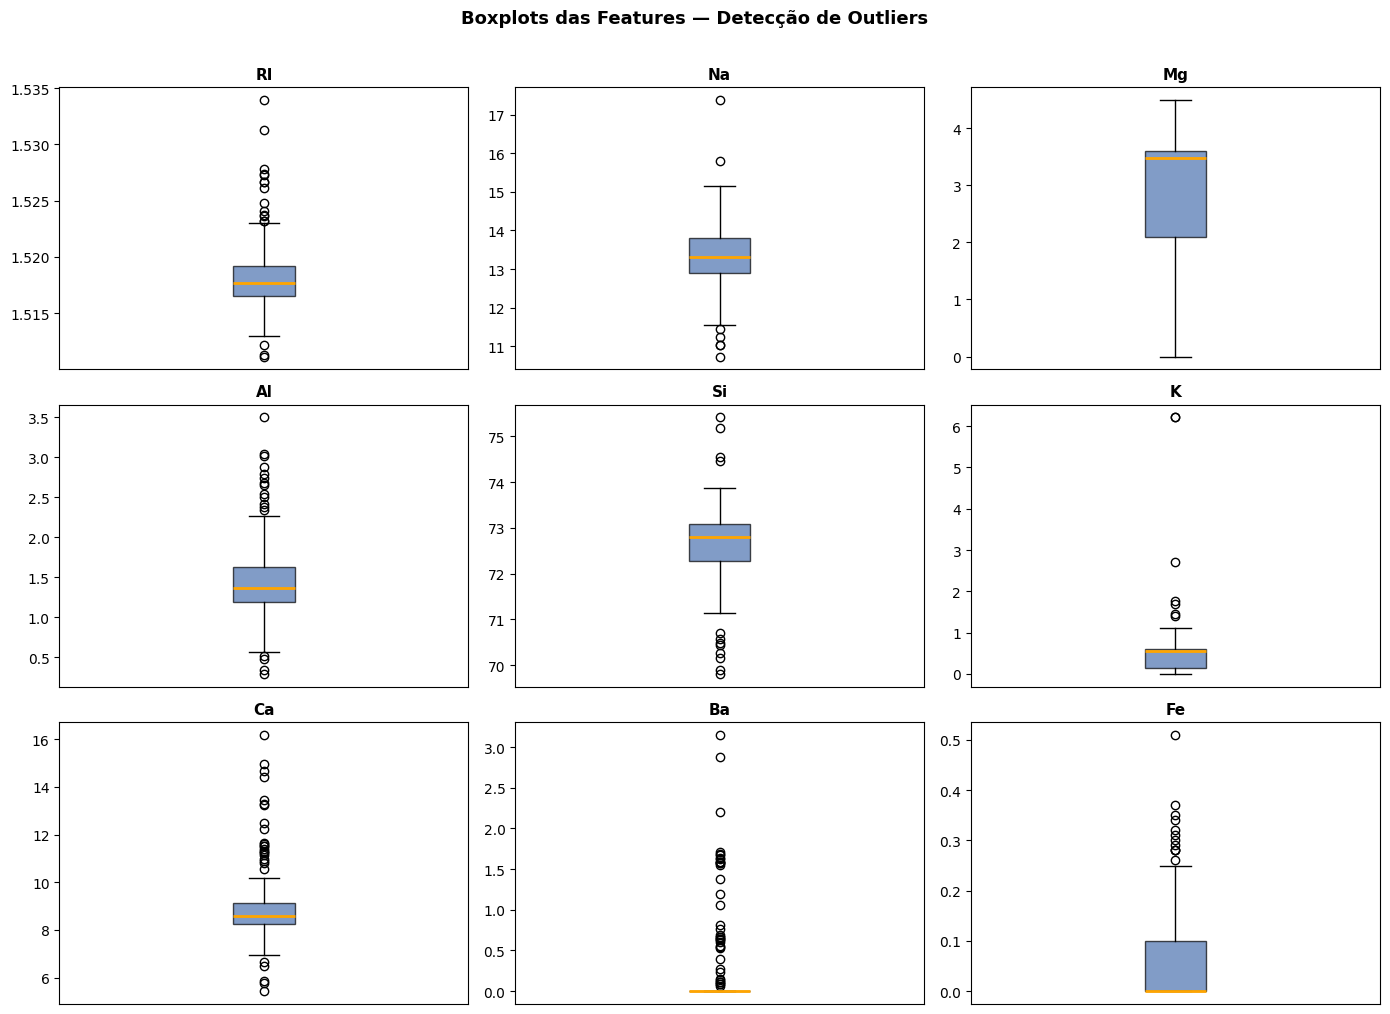

In [ ]:
# Boxplots para visualização de outliers
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for i, feat in enumerate(X.columns):
    axes[i].boxplot(X[feat], patch_artist=True,
                    boxprops=dict(facecolor='#4C72B0', alpha=0.7),
                    medianprops=dict(color='orange', linewidth=2))
    axes[i].set_title(feat, fontsize=11, fontweight='bold')
    axes[i].set_xticks([])

plt.suptitle('Boxplots das Features — Detecção de Outliers', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
from scipy import stats

# Remoção por Z-score (threshold = 3.5 para preservar mais amostras no dataset pequeno)
THRESHOLD = 3.5

z_scores = np.abs(stats.zscore(X))
outlier_mask = (z_scores < THRESHOLD).all(axis=1)

n_outliers = (~outlier_mask).sum()
print(f'=== REMOÇÃO DE OUTLIERS (Z-score > {THRESHOLD}) ===')
print(f'   Outliers detectados: {n_outliers}')
print(f'   Amostras antes: {len(X)}')

X_clean = X[outlier_mask].reset_index(drop=True)
y_clean = y[outlier_mask].reset_index(drop=True)

print(f'   Amostras após remoção: {len(X_clean)}')
print(f'\n⚠️  Usamos threshold 3.5 (em vez de 3.0) pois o dataset é pequeno (214 amostras).')
print('   Remover demais amostras prejudicaria especialmente as classes minoritárias.')

=== REMOÇÃO DE OUTLIERS (Z-score > 3.5) ===
   Outliers detectados: 11
   Amostras antes: 213
   Amostras após remoção: 202

⚠️  Usamos threshold 3.5 (em vez de 3.0) pois o dataset é pequeno (214 amostras).
   Remover demais amostras prejudicaria especialmente as classes minoritárias.


## ⚖️ Etapa 6 — Balanceamento de Classes com SMOTE

> O dataset tem classes com menos de 10 amostras (Tableware: ~9). Sem balanceamento, a árvore ignorará essas classes. O SMOTE gera amostras sintéticas interpoladas a partir dos vizinhos mais próximos de cada classe minoritária.

=== DISTRIBUIÇÃO ANTES DO SMOTE ===
Type
1    69
2    71
3    17
5     9
6     8
7    28
Name: count, dtype: int64

=== DISTRIBUIÇÃO APÓS SMOTE ===
Type
1    71
2    71
3    71
5    71
6    71
7    71
Name: count, dtype: int64

✅ Total de amostras: 426 (era 202)


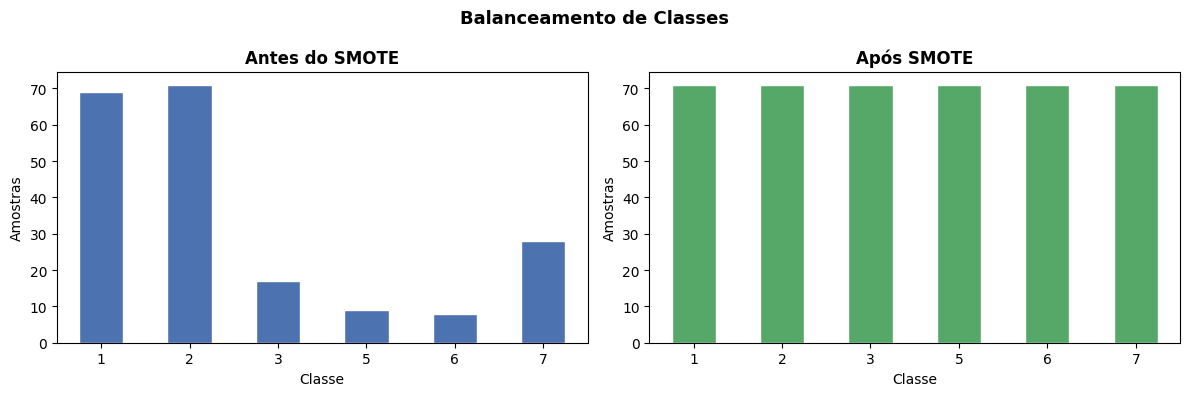

In [ ]:
from imblearn.over_sampling import SMOTE

print('=== DISTRIBUIÇÃO ANTES DO SMOTE ===')
print(y_clean.value_counts().sort_index())

# k_neighbors=3 pois algumas classes têm poucas amostras
smote = SMOTE(random_state=42, k_neighbors=3)
X_res, y_res = smote.fit_resample(X_clean, y_clean)

print(f'\n=== DISTRIBUIÇÃO APÓS SMOTE ===')
print(pd.Series(y_res).value_counts().sort_index())
print(f'\n✅ Total de amostras: {len(X_res)} (era {len(X_clean)})')

# Visualização antes x depois
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

y_clean.value_counts().sort_index().plot(kind='bar', ax=ax1, color='#4C72B0',
                                          edgecolor='white')
ax1.set_title('Antes do SMOTE', fontweight='bold')
ax1.set_xlabel('Classe'); ax1.set_ylabel('Amostras')
ax1.tick_params(axis='x', rotation=0)

pd.Series(y_res).value_counts().sort_index().plot(kind='bar', ax=ax2, color='#55A868',
                                                    edgecolor='white')
ax2.set_title('Após SMOTE', fontweight='bold')
ax2.set_xlabel('Classe'); ax2.set_ylabel('Amostras')
ax2.tick_params(axis='x', rotation=0)

plt.suptitle('Balanceamento de Classes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 🛠️ Etapa 7 — Engenharia de Features

Features binárias para `Ba` e `Fe` (muito esparsas) e razões entre óxidos quimicamente relevantes.

In [ ]:
X_eng = pd.DataFrame(X_res, columns=X_clean.columns)

# Features binárias para atributos esparsos
X_eng['Ba_presente'] = (X_eng['Ba'] > 0).astype(int)
X_eng['Fe_presente'] = (X_eng['Fe'] > 0).astype(int)

# Razões entre óxidos com significado químico
X_eng['Na_Ca_ratio'] = X_eng['Na'] / (X_eng['Ca'] + 1e-5)
X_eng['Si_Al_ratio'] = X_eng['Si'] / (X_eng['Al'] + 1e-5)
X_eng['Mg_Al_ratio'] = X_eng['Mg'] / (X_eng['Al'] + 1e-5)

print('=== FEATURES APÓS ENGENHARIA ===')
print(f'   Features originais: {len(X_clean.columns)}')
print(f'   Features após engenharia: {len(X_eng.columns)}')
print(f'   Novas features: {[c for c in X_eng.columns if c not in X_clean.columns]}')
X_eng.head(3)

=== FEATURES APÓS ENGENHARIA ===
   Features originais: 9
   Features após engenharia: 14
   Novas features: ['Ba_presente', 'Fe_presente', 'Na_Ca_ratio', 'Si_Al_ratio', 'Mg_Al_ratio']


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Ba_presente,Fe_presente,Na_Ca_ratio,Si_Al_ratio,Mg_Al_ratio
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,0,0,1.558855,65.253952,4.081781
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,0,0,1.773944,53.477548,2.647039
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,0,0,1.739072,47.395796,2.305180


## ✂️ Etapa 8 — Divisão Estratificada dos Dados

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_eng,
    y_res,
    test_size=0.2,
    random_state=42,
    stratify=y_res  # Garante proporção de classes em treino e teste
)

print('=== DIVISÃO DOS DADOS ===')
print(f'   Treino:  {X_train.shape[0]} amostras ({X_train.shape[0]/len(X_eng)*100:.1f}%)')
print(f'   Teste:   {X_test.shape[0]} amostras ({X_test.shape[0]/len(X_eng)*100:.1f}%)')
print(f'   Features: {X_train.shape[1]}')
print()
print('Distribuição de classes no treino:')
print(pd.Series(y_train).value_counts().sort_index())
print('\nDistribuição de classes no teste:')
print(pd.Series(y_test).value_counts().sort_index())

=== DIVISÃO DOS DADOS ===
   Treino:  340 amostras (79.8%)
   Teste:   86 amostras (20.2%)
   Features: 14

Distribuição de classes no treino:
Type
1    57
2    57
3    57
5    56
6    56
7    57
Name: count, dtype: int64

Distribuição de classes no teste:
Type
1    14
2    14
3    14
5    15
6    15
7    14
Name: count, dtype: int64


## 🌳 Etapa 9 — Treinamento e Otimização da Árvore de Decisão

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    'criterion':          ['gini', 'entropy'],
    'max_depth':          [3, 5, 7, 10, None],
    'min_samples_split':  [2, 5, 10],
    'min_samples_leaf':   [1, 2, 4],
    'max_features':       [None, 'sqrt', 'log2']
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    param_grid,
    cv=cv,
    scoring='f1_macro',   # Adequado para multiclasse desbalanceada
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print('\n=== MELHORES HIPERPARÂMETROS ===')
for param, val in grid_search.best_params_.items():
    print(f'   {param}: {val}')
print(f'\n   F1-macro (validação cruzada): {grid_search.best_score_:.4f}')

best_model = grid_search.best_estimator_

Fitting 10 folds for each of 270 candidates, totalling 2700 fits

=== MELHORES HIPERPARÂMETROS ===
   criterion: entropy
   max_depth: 7
   max_features: None
   min_samples_leaf: 1
   min_samples_split: 2

   F1-macro (validação cruzada): 0.8488


## 📈 Etapa 10 — Avaliação e Visualização dos Resultados

In [ ]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, accuracy_score, f1_score
)

y_pred = best_model.predict(X_test)

nomes = {
    1: 'Build.Win.Float',
    2: 'Build.Win.NonFloat',
    3: 'Veh.Win.Float',
    5: 'Containers',
    6: 'Tableware',
    7: 'Headlamps'
}
classes = sorted(pd.Series(y_test).unique())
labels = [nomes.get(c, str(c)) for c in classes]

print('=== MÉTRICAS DE AVALIAÇÃO ===')
print(f'   Acurácia:  {accuracy_score(y_test, y_pred):.4f}')
print(f'   F1-macro:  {f1_score(y_test, y_pred, average="macro"):.4f}')
print(f'   F1-weighted: {f1_score(y_test, y_pred, average="weighted"):.4f}')
print()
print('=== RELATÓRIO POR CLASSE ===')
print(classification_report(y_test, y_pred, target_names=labels))

=== MÉTRICAS DE AVALIAÇÃO ===
   Acurácia:  0.8953
   F1-macro:  0.8907
   F1-weighted: 0.8932

=== RELATÓRIO POR CLASSE ===
                    precision    recall  f1-score   support

   Build.Win.Float       0.92      0.86      0.89        14
Build.Win.NonFloat       0.82      0.64      0.72        14
     Veh.Win.Float       0.87      0.93      0.90        14
        Containers       1.00      1.00      1.00        15
         Tableware       1.00      1.00      1.00        15
         Headlamps       0.76      0.93      0.84        14

          accuracy                           0.90        86
         macro avg       0.90      0.89      0.89        86
      weighted avg       0.90      0.90      0.89        86



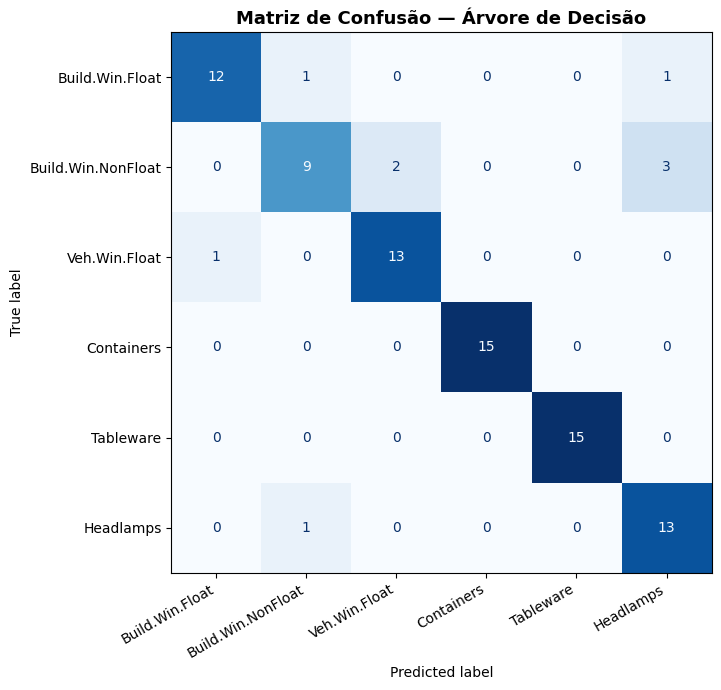

In [ ]:
# Matriz de confusão
fig, ax = plt.subplots(figsize=(9, 7))
cm = confusion_matrix(y_test, y_pred, labels=classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Matriz de Confusão — Árvore de Decisão', fontsize=13, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

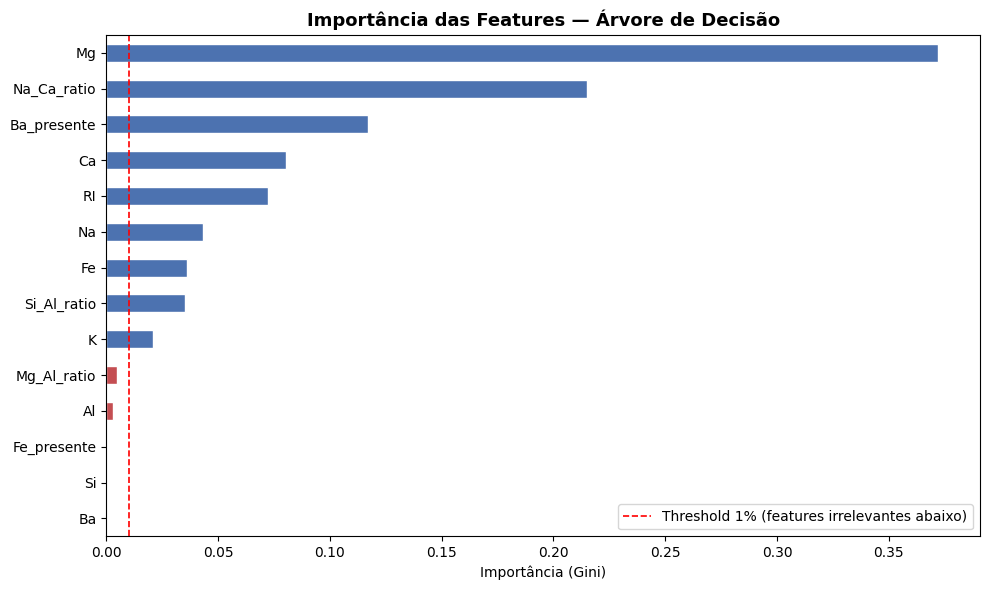

=== FEATURES COM BAIXA IMPORTÂNCIA (<1%) ===
   Ba: 0.0000
   Si: 0.0000
   Fe_presente: 0.0000
   Al: 0.0032
   Mg_Al_ratio: 0.0047

   Considere remover essas features e re-treinar.


In [ ]:
# Importância das features
importances = best_model.feature_importances_
feat_imp = pd.Series(importances, index=X_eng.columns).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#C44E52' if v < 0.01 else '#4C72B0' for v in feat_imp.values]
feat_imp.plot(kind='barh', ax=ax, color=colors, edgecolor='white')
ax.axvline(x=0.01, color='red', linestyle='--', linewidth=1.2,
           label='Threshold 1% (features irrelevantes abaixo)')
ax.set_title('Importância das Features — Árvore de Decisão', fontsize=13, fontweight='bold')
ax.set_xlabel('Importância (Gini)')
ax.legend()
plt.tight_layout()
plt.show()

print('=== FEATURES COM BAIXA IMPORTÂNCIA (<1%) ===')
baixas = feat_imp[feat_imp < 0.01]
if len(baixas) > 0:
    for feat, val in baixas.items():
        print(f'   {feat}: {val:.4f}')
    print('\n   Considere remover essas features e re-treinar.')
else:
    print('   Todas as features têm importância >= 1%.')

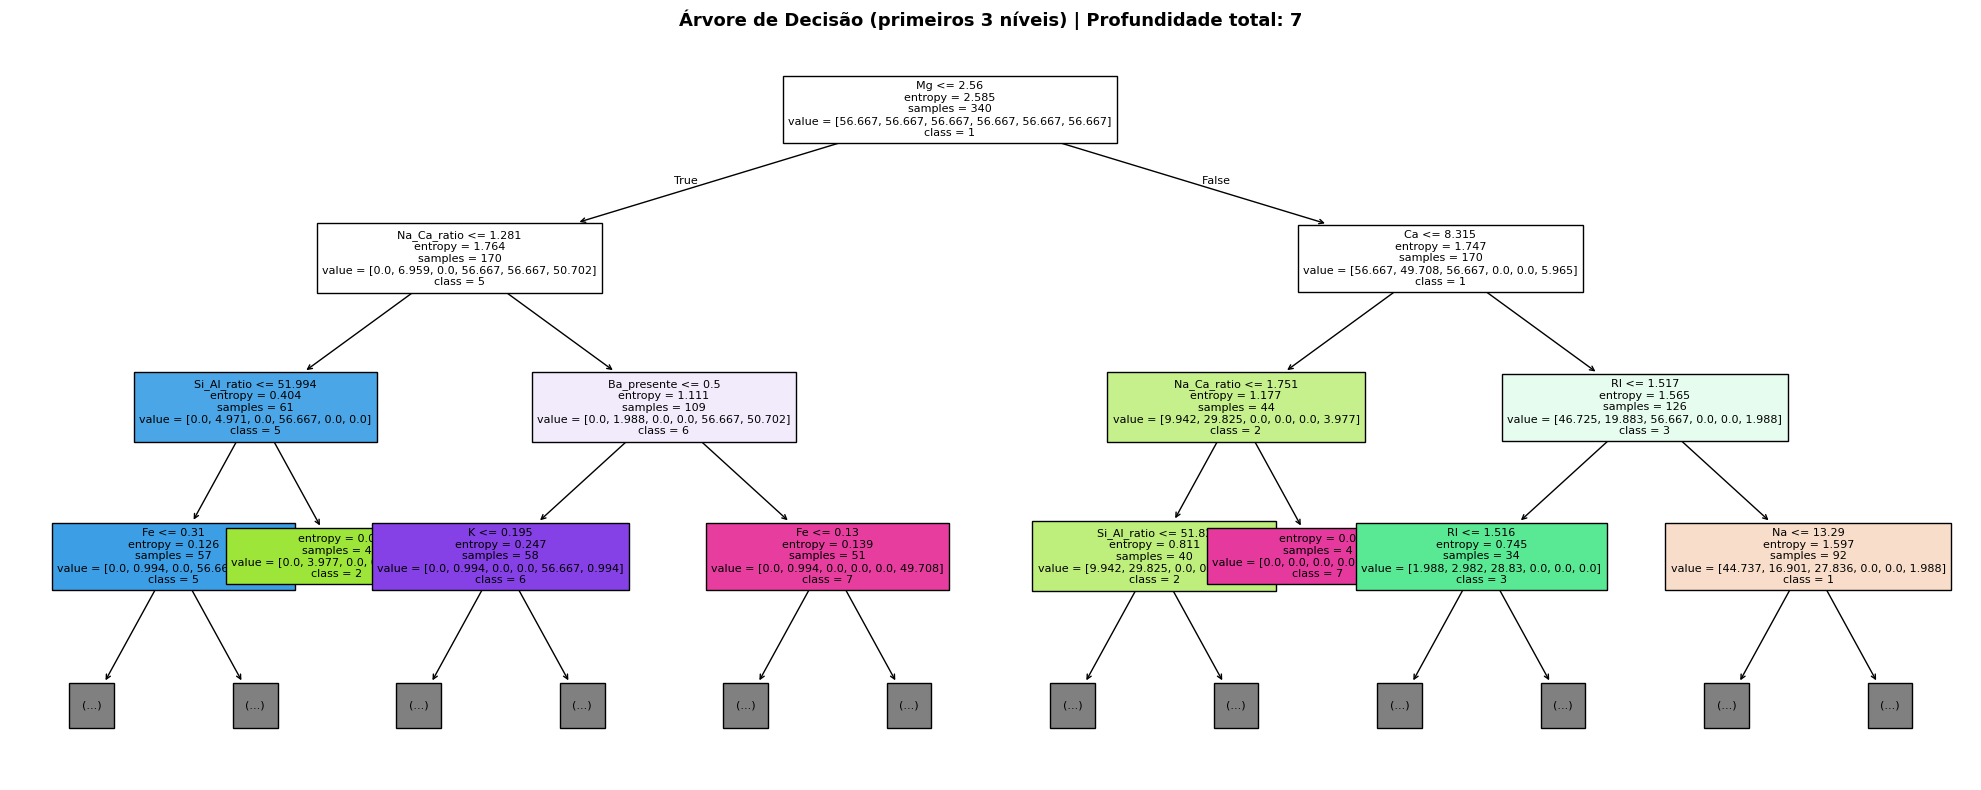

In [ ]:
from sklearn.tree import plot_tree

# Visualização da árvore (limitada a 3 níveis para legibilidade)
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(
    best_model,
    feature_names=list(X_eng.columns),
    class_names=[str(c) for c in sorted(pd.Series(y_train).unique())],
    filled=True,
    max_depth=3,      # Mostra apenas os 3 primeiros níveis
    fontsize=8,
    ax=ax,
    impurity=True,
    proportion=False
)
ax.set_title(
    f'Árvore de Decisão (primeiros 3 níveis) | Profundidade total: {best_model.get_depth()}',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.show()

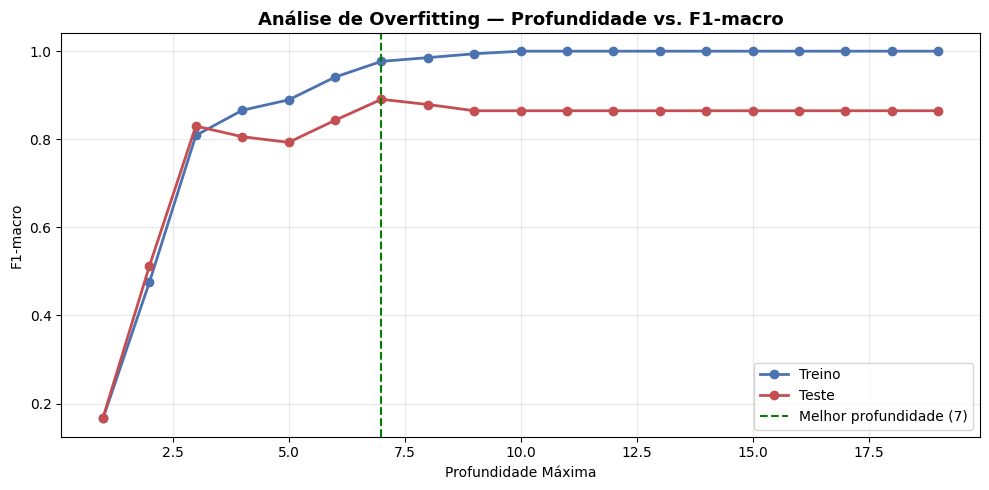


=== RESUMO FINAL ===
   Profundidade da árvore: 7
   Número de folhas: 34
   F1-macro (teste): 0.8907
   Acurácia (teste): 0.8953


In [ ]:
# Análise de profundidade vs. F1-macro (curva de overfitting)
depths = range(1, 20)
train_scores, val_scores = [], []

for d in depths:
    clf = DecisionTreeClassifier(
        max_depth=d,
        class_weight='balanced',
        criterion=grid_search.best_params_['criterion'],
        min_samples_leaf=grid_search.best_params_['min_samples_leaf'],
        random_state=42
    )
    clf.fit(X_train, y_train)
    train_scores.append(f1_score(y_train, clf.predict(X_train), average='macro'))
    val_scores.append(f1_score(y_test, clf.predict(X_test), average='macro'))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(depths, train_scores, 'o-', label='Treino', color='#4C72B0', linewidth=2)
ax.plot(depths, val_scores,   'o-', label='Teste',  color='#C44E52', linewidth=2)
ax.axvline(x=best_model.get_depth(), color='green', linestyle='--',
           label=f'Melhor profundidade ({best_model.get_depth()})')
ax.set_xlabel('Profundidade Máxima')
ax.set_ylabel('F1-macro')
ax.set_title('Análise de Overfitting — Profundidade vs. F1-macro', fontsize=13, fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('\n=== RESUMO FINAL ===')
print(f'   Profundidade da árvore: {best_model.get_depth()}')
print(f'   Número de folhas: {best_model.get_n_leaves()}')
print(f'   F1-macro (teste): {f1_score(y_test, y_pred, average="macro"):.4f}')
print(f'   Acurácia (teste): {accuracy_score(y_test, y_pred):.4f}')

---
## ✅ Conclusão do Pipeline

| Etapa | Ação | Justificativa |
|---|---|---|
| 1 | Remoção do ID | Evita overfitting trivial |
| 2 | Verificação de duplicatas | Garante integridade dos dados |
| 3 | Outliers (Z-score > 3.5) | Previne splits espúrios em Ba e Fe |
| 4 | SMOTE | Equilíbrio entre as 6 classes desiguais |
| 5 | Engenharia de features | Captura presença de Ba/Fe e razões químicas |
| 6 | Divisão estratificada | Mantém proporção de classes em treino/teste |
| 7 | GridSearchCV + StratifiedKFold | Otimização robusta dos hiperparâmetros |
| 8 | Avaliação com F1-macro | Métrica justa para classes desbalanceadas |

---
*Dataset: German, B. (1987). Glass Identification. UCI Machine Learning Repository. https://doi.org/10.24432/C5WW2P*